In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


In [2]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [3]:
#Importing Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import warnings

warnings.filterwarnings("ignore")

In [6]:
data = pd.read_excel("C:\\Users\\prana\\Downloads\\crop yield data sheet (1).xlsx")


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109 entries, 0 to 108
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Rain Fall (mm)  99 non-null     float64
 1   Fertilizer      99 non-null     float64
 2   Temperatue      100 non-null    object 
 3   Nitrogen (N)    99 non-null     float64
 4   Phosphorus (P)  99 non-null     float64
 5   Potassium (K)   99 non-null     float64
 6   Yeild (Q/acre)  99 non-null     float64
dtypes: float64(6), object(1)
memory usage: 6.1+ KB


In [8]:
data.shape

(109, 7)

In [9]:
data.columns

Index(['Rain Fall (mm)', 'Fertilizer', 'Temperatue', 'Nitrogen (N)',
       'Phosphorus (P)', 'Potassium (K)', 'Yeild (Q/acre)'],
      dtype='object')

In [10]:
num_col=[]
for col in data.columns:
    if(data[col].dtypes!='object'):
        num_col.append(col)
        
print(f"There are total {len(num_col)} numerical columns in dataset ")
print(num_col)

There are total 6 numerical columns in dataset 
['Rain Fall (mm)', 'Fertilizer', 'Nitrogen (N)', 'Phosphorus (P)', 'Potassium (K)', 'Yeild (Q/acre)']


In [11]:
#Finding Categorical Columns
cat_col=[]
for col in data.columns:
    if(data[col].dtypes=='object'):
        cat_col.append(col)

print(f"There are total {len(cat_col)} categorical columns in dataset")
print(cat_col)

There are total 1 categorical columns in dataset
['Temperatue']


In [12]:
#Head
data.head()

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
0,1230.0,80.0,28,80.0,24.0,20.0,12.0
1,480.0,60.0,36,70.0,20.0,18.0,8.0
2,1250.0,75.0,29,78.0,22.0,19.0,11.0
3,450.0,65.0,35,70.0,19.0,18.0,9.0
4,1200.0,80.0,27,79.0,22.0,19.0,11.0


In [13]:
data.sample(5)

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
75,475.0,58.0,39,68.0,19.0,16.0,7.5
41,405.0,55.0,36,60.0,21.0,16.0,7.0
56,1280.0,73.0,28,75.0,24.0,19.0,11.0
19,1200.0,78.0,27,78.0,23.0,19.0,12.0
70,1245.0,77.0,27,75.0,22.0,20.0,9.5


In [14]:
data.isnull().mean()*100

Rain Fall (mm)    9.174312
Fertilizer        9.174312
Temperatue        8.256881
Nitrogen (N)      9.174312
Phosphorus (P)    9.174312
Potassium (K)     9.174312
Yeild (Q/acre)    9.174312
dtype: float64

In [15]:
data.dropna(inplace=True)

In [16]:
#Finding Duplicates
data.duplicated().sum()

np.int64(4)

In [17]:
#Removing Duplicates
data.drop_duplicates(inplace=True)

Distribution of Data

<Axes: title={'center': 'Rain Fall (mm)'}, ylabel='Density'>

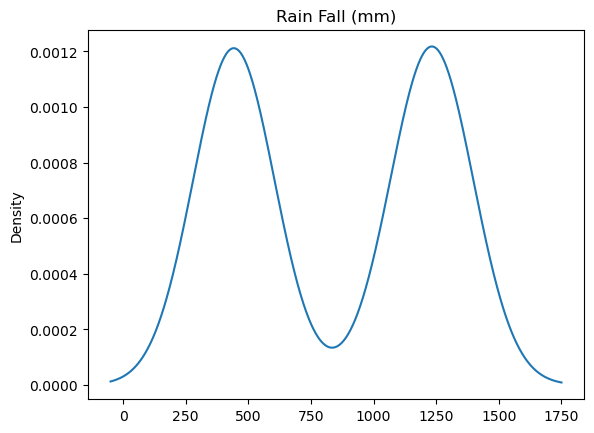

In [18]:
#'Rain Fall (mm)'
data['Rain Fall (mm)'].plot(kind='kde',title=f"Rain Fall (mm)")

<Axes: title={'center': 'Yeild (Q/acre)'}, ylabel='Density'>

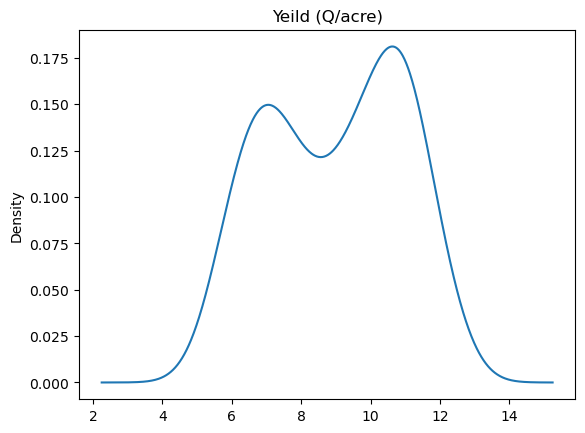

In [19]:
#'Yeild (Q/acre)'
data['Yeild (Q/acre)'].plot(kind='kde',title=f'Yeild (Q/acre)')

<Axes: title={'center': 'Potassium (K)'}, ylabel='Density'>

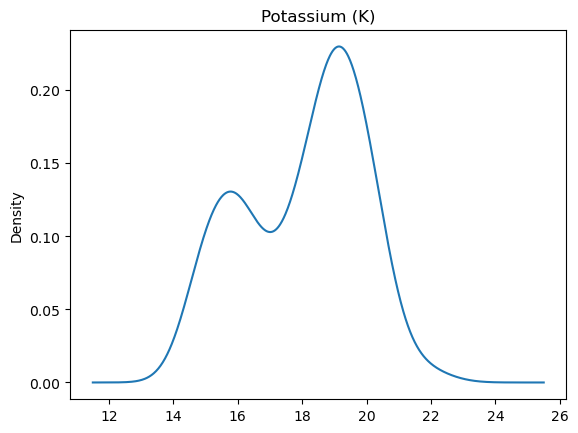

In [20]:
#'Potassium (K)'
data[ 'Potassium (K)'].plot(kind='kde',title=f'Potassium (K)')

<Axes: title={'center': 'Phosphorus (P)'}, ylabel='Density'>

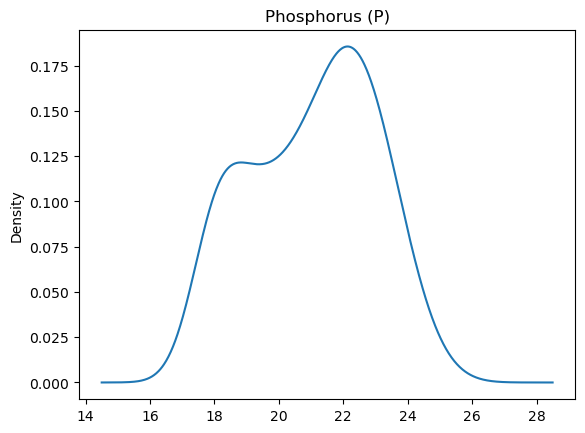

In [21]:
#'Phosphorus (P)'
data['Phosphorus (P)'].plot(kind='kde',title=f'Phosphorus (P)')

<Axes: title={'center': 'Nitrogen (N)'}, ylabel='Density'>

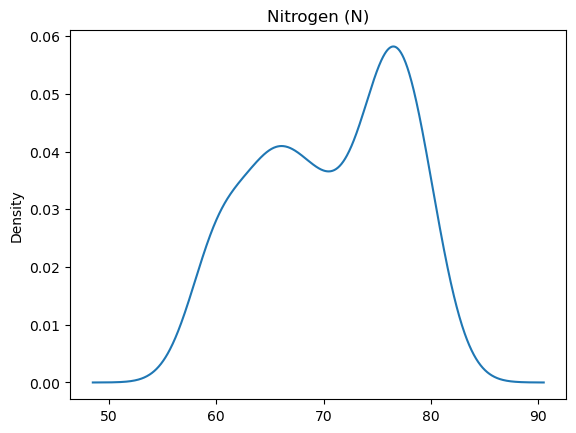

In [22]:
#'Nitrogen (N)'
data['Nitrogen (N)'].plot(kind='kde',title=f"Nitrogen (N)")

<Axes: title={'center': 'Temperatue'}, ylabel='Density'>

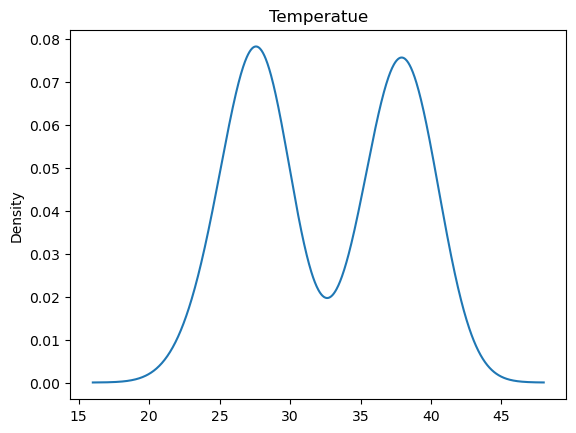

In [23]:
#'Temperatue'
data['Temperatue'].plot(kind='kde',title=f"Temperatue")

<Axes: title={'center': 'Fertilizer'}, ylabel='Density'>

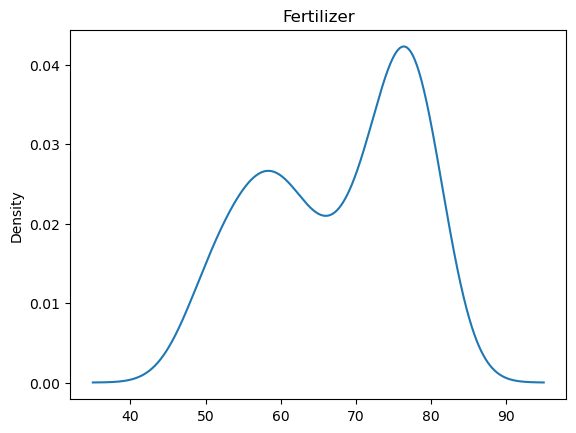

In [24]:
#'Fertilizer'
data['Fertilizer'].plot(kind='kde',title=f"Fertilizer")

In [25]:
#Finding Outliers
norm_dist=[]
for col in data.columns:
      if((data[col].skew()>-0.5) &(data[col].skew()<0.5)):
            norm_dist.append(col)
print(f"There are total {len(norm_dist)} columns that have normal distribution")
print(norm_dist)

There are total 7 columns that have normal distribution
['Rain Fall (mm)', 'Fertilizer', 'Temperatue', 'Nitrogen (N)', 'Phosphorus (P)', 'Potassium (K)', 'Yeild (Q/acre)']


In [26]:
#Outlier Detection
for col in norm_dist:
    mean=data[col].mean()
    std=data[col].std()
    max=mean+(3*std)
    min=mean-(3*std)
    print(data[(data[col]>max) |(data[col]<min)])

Empty DataFrame
Columns: [Rain Fall (mm), Fertilizer, Temperatue, Nitrogen (N), Phosphorus (P), Potassium (K), Yeild (Q/acre)]
Index: []
Empty DataFrame
Columns: [Rain Fall (mm), Fertilizer, Temperatue, Nitrogen (N), Phosphorus (P), Potassium (K), Yeild (Q/acre)]
Index: []
Empty DataFrame
Columns: [Rain Fall (mm), Fertilizer, Temperatue, Nitrogen (N), Phosphorus (P), Potassium (K), Yeild (Q/acre)]
Index: []
Empty DataFrame
Columns: [Rain Fall (mm), Fertilizer, Temperatue, Nitrogen (N), Phosphorus (P), Potassium (K), Yeild (Q/acre)]
Index: []
Empty DataFrame
Columns: [Rain Fall (mm), Fertilizer, Temperatue, Nitrogen (N), Phosphorus (P), Potassium (K), Yeild (Q/acre)]
Index: []
Empty DataFrame
Columns: [Rain Fall (mm), Fertilizer, Temperatue, Nitrogen (N), Phosphorus (P), Potassium (K), Yeild (Q/acre)]
Index: []
Empty DataFrame
Columns: [Rain Fall (mm), Fertilizer, Temperatue, Nitrogen (N), Phosphorus (P), Potassium (K), Yeild (Q/acre)]
Index: []


EDA
Univariate Analysis

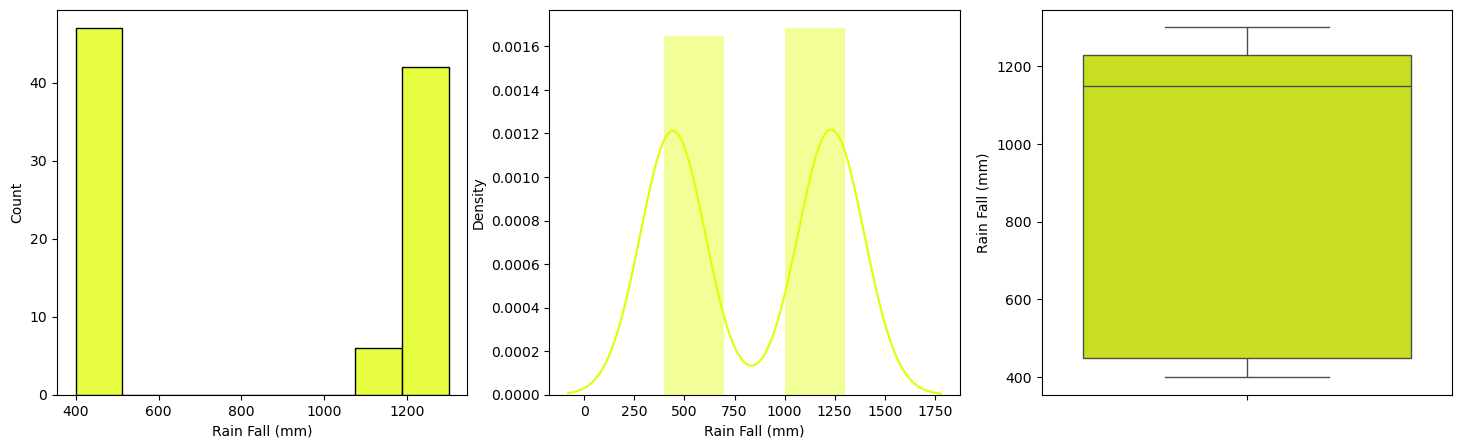

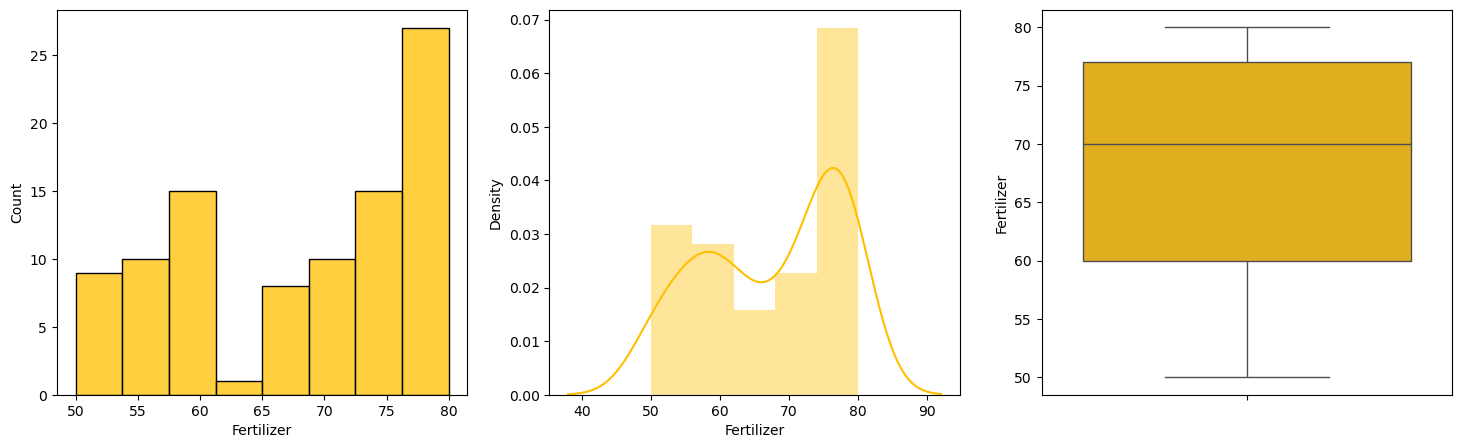

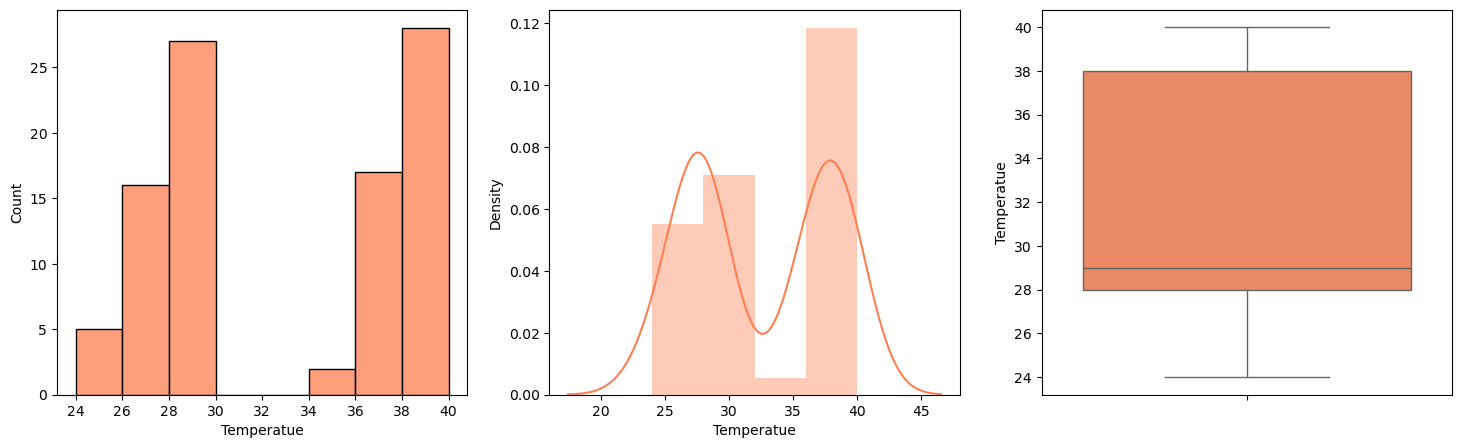

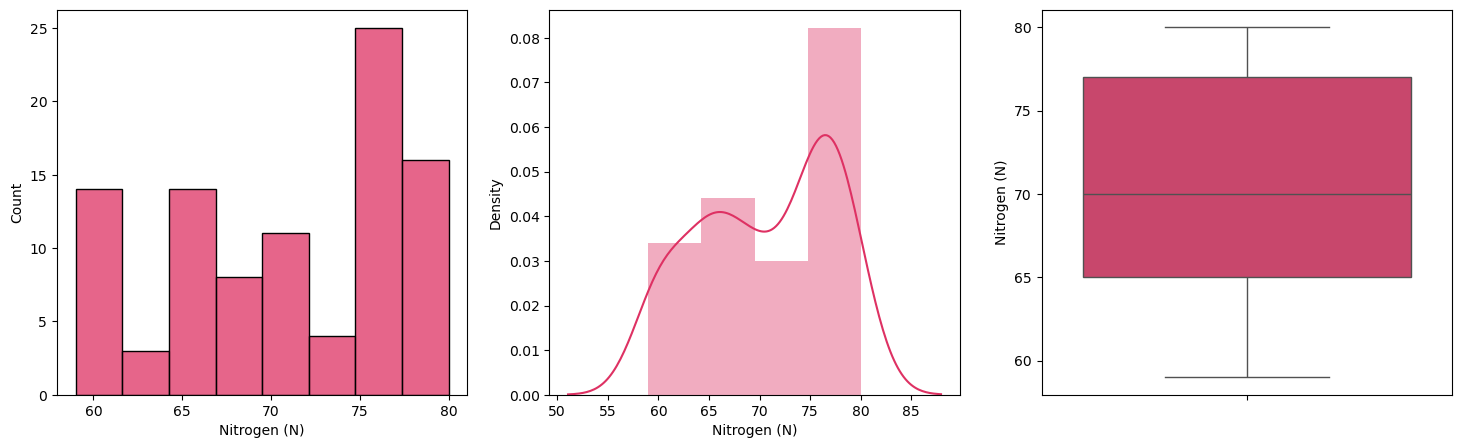

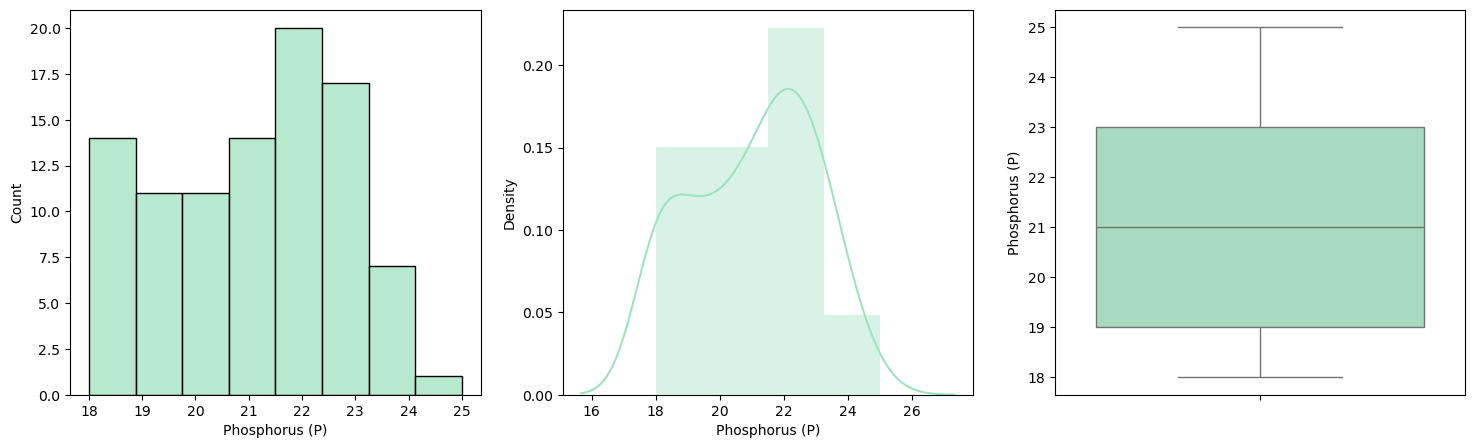

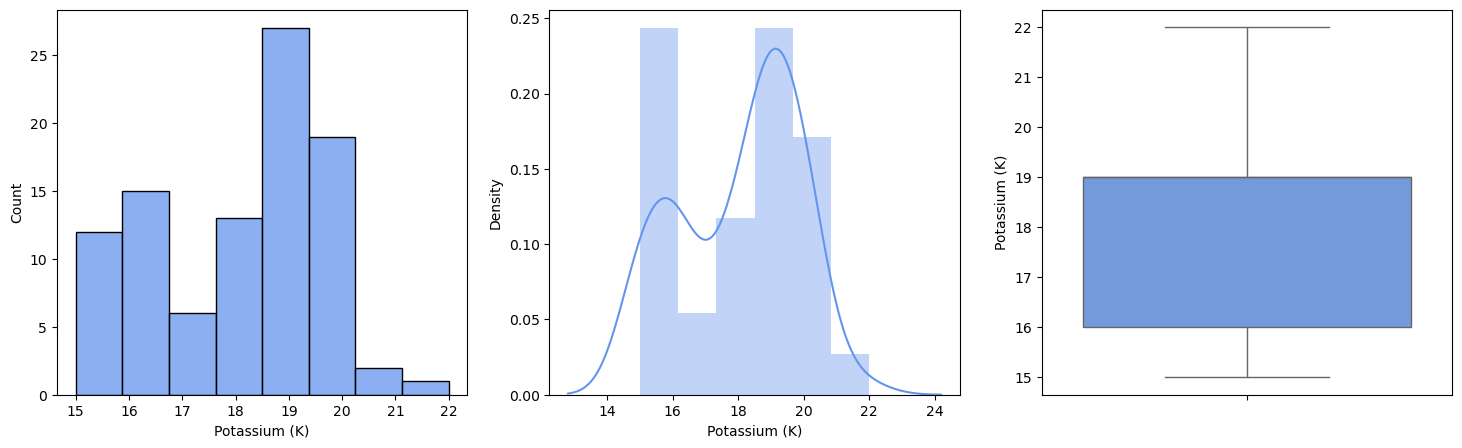

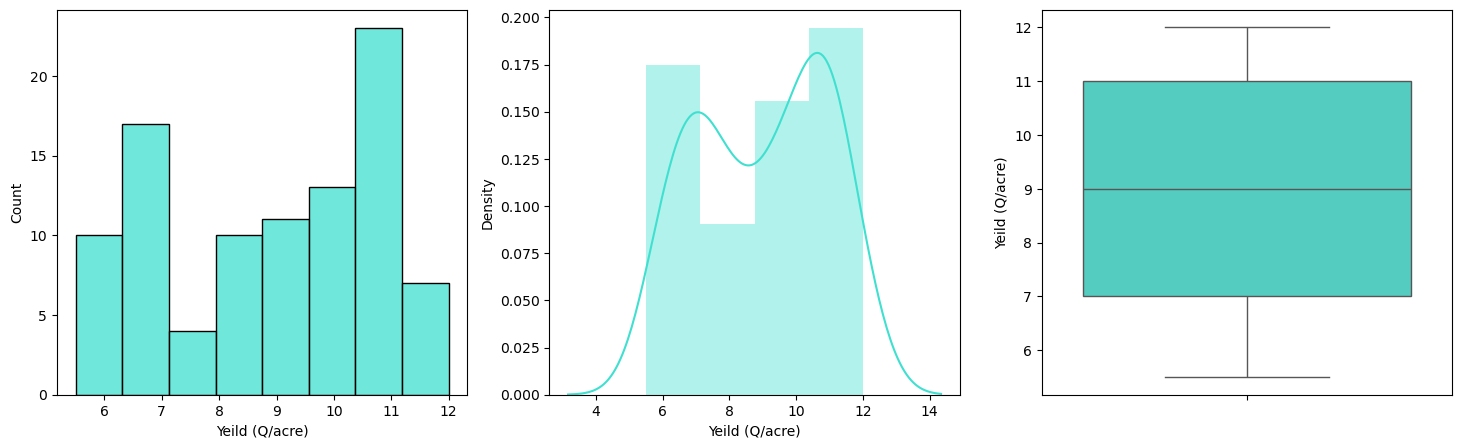

In [27]:
c=['#DFFF00','#FFBF00','#FF7F50','#DE3163','#9FE2BF','#6495ED','#40E0D0']
for i in zip(data.columns,c):
    fig,axes=plt.subplots(1,3,figsize=(18,5))
    sns.histplot(data[i[0]],ax=axes[0],color=i[1])
    sns.distplot(data[i[0]],ax=axes[1],color=i[1])
    sns.boxplot(data[i[0]],ax=axes[2],color=i[1])
    plt.show()

Bivariate Analysis

In [28]:
data.sample(5)

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
80,1200.0,77.0,29,76.0,22.0,19.0,9.5
61,425.0,70.0,39,70.0,20.0,16.0,6.5
38,1250.0,75.0,26,75.0,22.0,19.0,12.0
75,475.0,58.0,39,68.0,19.0,16.0,7.5
4,1200.0,80.0,27,79.0,22.0,19.0,11.0


In [29]:
temp=data.groupby('Temperatue')
D=[]
for group,data in temp:
    D.append(pd.DataFrame(temp.get_group(group)))

In [30]:
#For Temperatue 24
D[0].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,1225.00,70.00,24.0,70.00,22.0,18.00,10.0
max,1300.00,79.00,24.0,79.00,22.0,19.00,11.0
mean,1256.25,72.25,24.0,72.25,22.0,18.25,10.5


In [31]:
#For Temperatue 25
D[1].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,1175.0,77.0,25.0,75.0,22.0,19.0,11.0
max,1175.0,77.0,25.0,75.0,22.0,19.0,11.0
mean,1175.0,77.0,25.0,75.0,22.0,19.0,11.0


In [32]:
#For Temperatue 26
D[2].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,1150.0,75.000000,26.0,75.000000,21.0,19.000000,11.000000
max,1280.0,80.000000,26.0,80.000000,24.0,20.000000,12.000000
mean,1247.5,77.833333,26.0,76.333333,23.0,19.333333,11.333333


In [35]:
#For Temperatue 27
D[3].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,1200.0,75.0,27.0,75.0,21.0,19.0,9.5
max,1275.0,80.0,27.0,79.0,23.0,20.0,12.0
mean,1221.5,77.1,27.0,77.3,22.1,19.6,10.9


In [34]:
#For Temperatue 28
D[4].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,1150.000000,70.0,28.0,70.000000,21.000000,19.000000,9.000000
max,1300.000000,80.0,28.0,80.000000,24.000000,22.000000,12.000000
mean,1241.944444,76.5,28.0,76.777778,22.777778,19.833333,10.611111


In [33]:
#For Temperatue 29
D[5].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,1150.000000,72.000000,29.0,73.000000,21.000000,18.000000,9.000000
max,1250.000000,79.000000,29.0,79.000000,23.000000,20.000000,11.000000
mean,1210.555556,75.444444,29.0,75.666667,22.222222,19.222222,10.055556


In [36]:
#For Temperatue 34
D[6].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,500.0,70.0,34.0,74.0,22.0,16.0,10.0
max,500.0,70.0,34.0,74.0,22.0,16.0,10.0
mean,500.0,70.0,34.0,74.0,22.0,16.0,10.0


In [37]:
#For Temperatue 35
D[7].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,450.0,65.0,35.0,70.0,19.0,18.0,9.0
max,450.0,65.0,35.0,70.0,19.0,18.0,9.0
mean,450.0,65.0,35.0,70.0,19.0,18.0,9.0


In [38]:
#For Temperatue 36
D[8].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,405.000000,55.000000,36.0,60.000000,19.000000,15.000000,7.000000
max,480.000000,72.000000,36.0,72.000000,25.000000,18.000000,8.000000
mean,446.428571,61.714286,36.0,67.285714,21.142857,16.571429,7.285714


In [39]:
#For Temperatue 37
D[9].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,410.0,50.0,37.0,59.0,18.0,15.0,6.00
max,500.0,65.0,37.0,68.0,22.0,19.0,9.00
mean,450.5,55.3,37.0,63.9,19.4,17.4,7.75


In [40]:
#For Temperatue 38
D[10].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,400.0,52.0,38.0,60.0,19.0,15.0,6.5
max,475.0,65.0,38.0,68.0,22.0,18.0,8.5
mean,438.5,57.7,38.0,64.1,19.8,16.6,7.5


In [41]:
#For Temperatue 39
D[11].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,400.000000,50.000000,39.0,60.000000,18.0,15.000000,5.500000
max,475.000000,70.000000,39.0,70.000000,21.0,19.000000,8.500000
mean,435.357143,60.571429,39.0,64.214286,19.0,16.214286,6.642857


In [42]:
#For Temperatue 40
D[12].agg(['min','max','mean'])

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K),Yeild (Q/acre)
min,400.0,50.00,40.0,60.0,18.00,15.0,6.00
max,450.0,59.00,40.0,67.0,19.00,16.0,7.50
mean,427.5,54.25,40.0,64.0,18.25,15.5,6.75


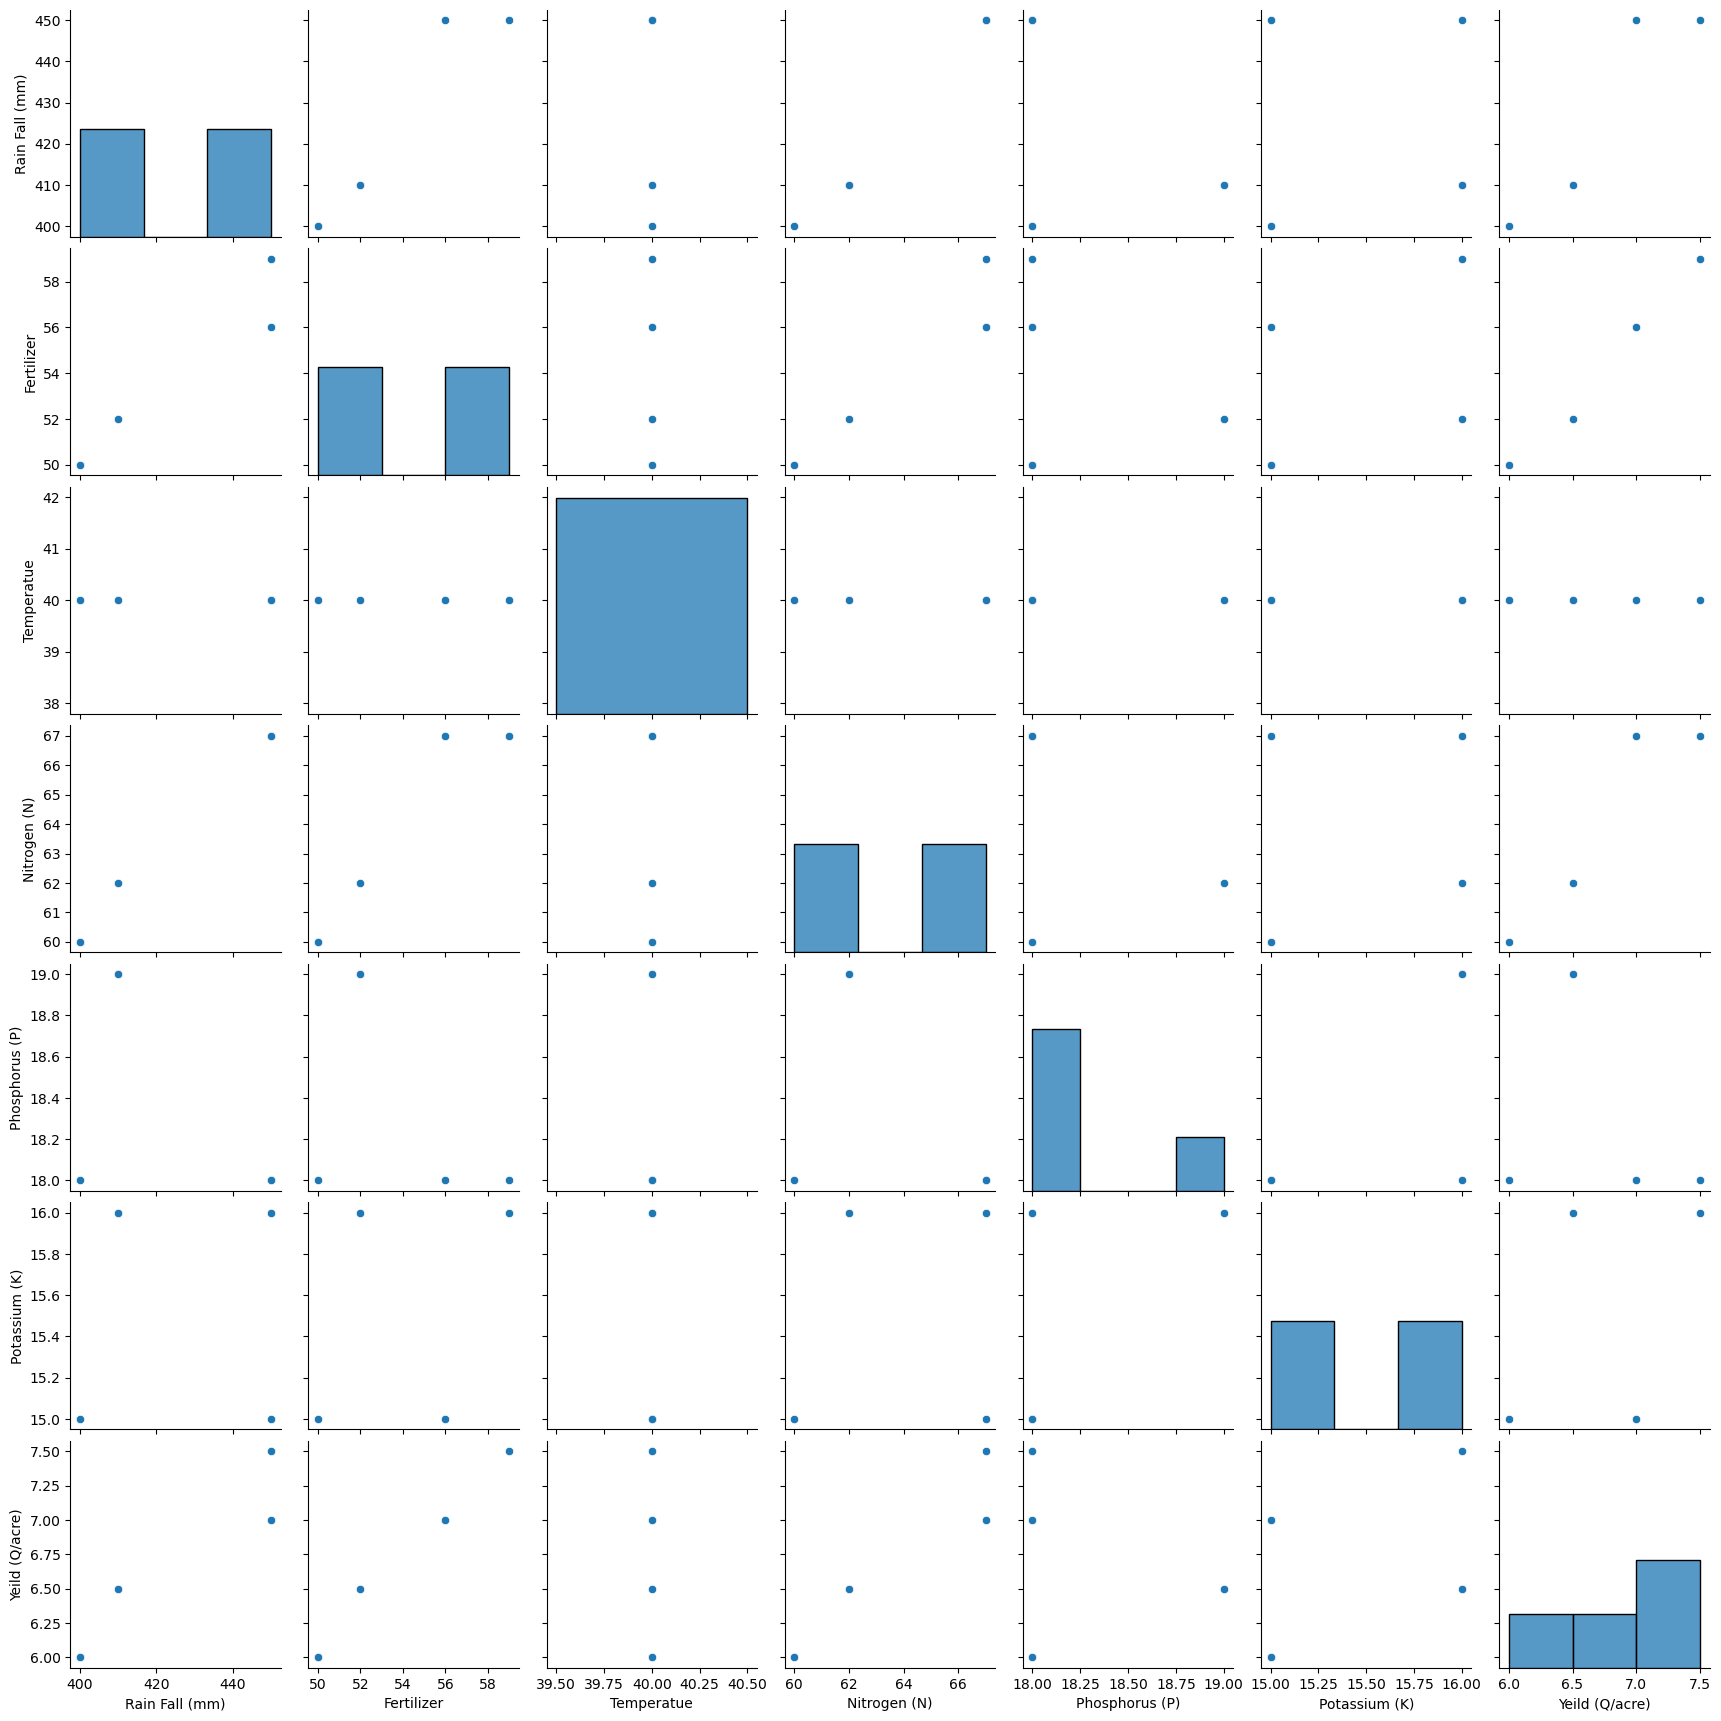

In [43]:
sns.pairplot(data)

<Axes: >

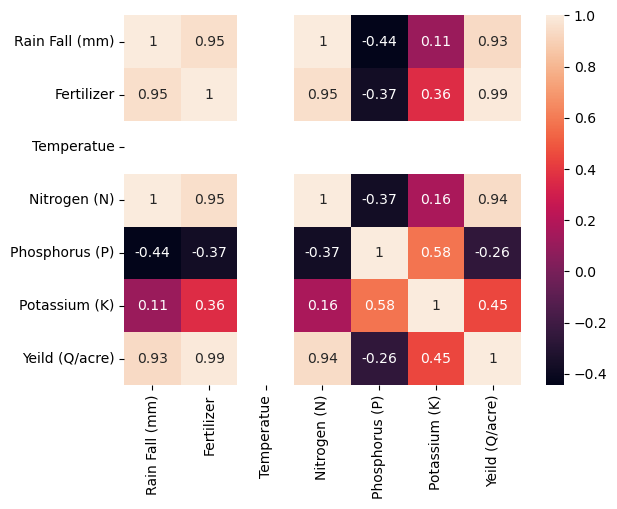

In [44]:
#Heat map
corr=data.corr()
sns.heatmap(corr,annot=True)

Feature Engineering

In [45]:
#Feature and Target
Feature=data.drop(columns={'Yeild (Q/acre)'})
Target=data['Yeild (Q/acre)']

In [46]:
#Feature Sample
Feature.head()

,Rain Fall (mm),Fertilizer,Temperatue,Nitrogen (N),Phosphorus (P),Potassium (K)
63,450.0,56.0,40,67.0,18.0,15.0
71,450.0,59.0,40,67.0,18.0,16.0
77,400.0,50.0,40,60.0,18.0,15.0
89,410.0,52.0,40,62.0,19.0,16.0


In [47]:
#Target Sample
Target.head()

63    7.0
71    7.5
77    6.0
89    6.5
Name: Yeild (Q/acre), dtype: float64

In [48]:
#Train_Test_Split
from sklearn.model_selection import train_test_split as tts
f_train,f_test,t_train,t_test=tts(Feature,Target,test_size=0.4)

In [49]:
#Feature Scaling
from sklearn.preprocessing import StandardScaler

#Object Creation
scaler=StandardScaler()

#Fitting
f_train_scaled=pd.DataFrame(scaler.fit_transform(f_train),columns=Feature.columns)

#Transformation
f_test_scaled=pd.DataFrame(scaler.transform(f_test),columns=Feature.columns)

In [53]:
conda install -c conda-forge mlxtend


3 channel Terms of Service accepted
Retrieving notices: done
Channels:
 - conda-forge
 - defaults
Platform: win-64
Solving environment: done

## Package Plan ##

  environment location: c:\Users\prana\anaconda3

  added / updated specs:
    - mlxtend


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    ca-certificates-2025.10.5  |       h4c7d964_0         153 KB  conda-forge
    certifi-2025.10.5          |     pyhd8ed1ab_0         156 KB  conda-forge
    mlxtend-0.23.4             |     pyhd8ed1ab_0         1.2 MB  conda-forge
    openssl-3.1.0              |       hcfcfb64_3         7.1 MB  conda-forge
    ucrt-10.0.26100.0          |       h57928b3_0         678 KB  conda-forge
    ------------------------------------------------------------
                                           Total:         9.3 MB

The following NEW packages will be INSTALLED:

  mlxtend            conda-forge/no



==> WARNING: A newer version of conda exists. <==
    current version: 25.5.1
    latest version: 25.9.1

Please update conda by running

    $ conda update -n base -c defaults conda




In [54]:
#Feature Selection 
import mlxtend
from mlxtend.feature_selection import ExhaustiveFeatureSelector as EFS
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
lr = LinearRegression()
dtr=DecisionTreeRegressor()
models=[lr,dtr]

for model in models:
    efs = EFS(model, 
          min_features=1,
          max_features=6,
          scoring='neg_mean_squared_error',
          cv=2)

    efs.fit(f_train, t_train)

    print('Best MSE score: %.2f' % efs.best_score_ * (-1))
    print('Best subset:', efs.best_idx_)
    print(efs.best_feature_names_)
    print(efs.best_score_)

Features: 1/633


Best subset: (0,)
('Rain Fall (mm)',)
-2.25


Features: 63/63


Best subset: (0,)
('Rain Fall (mm)',)
-2.25


In [55]:
df = pd.DataFrame.from_dict(efs.get_metric_dict()).T
df.sort_values('avg_score', inplace=True, ascending=False)
df

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
0,"(0,)","[-2.25, -2.25]",-2.25,"(Rain Fall (mm),)",0.0,0.0,0.0
47,"(0, 2, 3, 4)","[-2.25, -2.25]",-2.25,"(Rain Fall (mm), Temperatue, Nitrogen (N), Pho...",0.0,0.0,0.0
34,"(1, 3, 4)","[-2.25, -2.25]",-2.25,"(Fertilizer, Nitrogen (N), Phosphorus (P))",0.0,0.0,0.0
35,"(1, 3, 5)","[-2.25, -2.25]",-2.25,"(Fertilizer, Nitrogen (N), Potassium (K))",0.0,0.0,0.0
36,"(1, 4, 5)","[-2.25, -2.25]",-2.25,"(Fertilizer, Phosphorus (P), Potassium (K))",0.0,0.0,0.0
...,...,...,...,...,...,...,...
26,"(0, 2, 4)","[-2.25, -2.25]",-2.25,"(Rain Fall (mm), Temperatue, Phosphorus (P))",0.0,0.0,0.0
27,"(0, 2, 5)","[-2.25, -2.25]",-2.25,"(Rain Fall (mm), Temperatue, Potassium (K))",0.0,0.0,0.0
28,"(0, 3, 4)","[-2.25, -2.25]",-2.25,"(Rain Fall (mm), Nitrogen (N), Phosphorus (P))",0.0,0.0,0.0
29,"(0, 3, 5)","[-2.25, -2.25]",-2.25,"(Rain Fall (mm), Nitrogen (N), Potassium (K))",0.0,0.0,0.0


Model Building

In [56]:
#Importing Required Libraries
from sklearn.linear_model import LinearRegression

#Model Creation
model=LinearRegression()

#Model Training
model.fit(f_train,t_train)

#Model Prediction
t_pred=model.predict(f_test)

#Model Performance
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
print(f"Mean Squared Error of model is {mean_squared_error(t_test,t_pred)}")
print(f"R2 score of model is {r2_score(t_test,t_pred)*100}")

Mean Squared Error of model is 0.13637780528363913
R2 score of model is -118.2044884538226


In [57]:
#Performance of training data
#Model Prediction
train_pred=model.predict(f_train)

#Model Performance
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
print(f"Mean Squared Error of model is {mean_squared_error(t_test,train_pred)}")
print(f"R2 score of model is {r2_score(t_test,t_pred)*100}")

Mean Squared Error of model is 0.9999999999999982
R2 score of model is -118.2044884538226
